# EDA - Machine Maintenance Data

I used this notebook to understand the machine readings before our group trains the models. I checked missing values, unusual sensor readings and which columns might give away the maintenance label. The original CSV is not changed.

## 1. Load the dataset


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
paths = [Path("data/proj_machine_readings.csv"), Path("../data/proj_machine_readings.csv"), Path("proj_machine_readings.csv")]
path = next((p for p in paths if p.exists()), None)
if path is None:
    raise FileNotFoundError("Put proj_machine_readings.csv in the data folder first.")
df = pd.read_csv(path, parse_dates=["timestamp"])
print("Rows and columns:", df.shape)
print("Machines:", df["machine_id"].nunique())
df.head()


Rows and columns: (100000, 13)
Machines: 50


,timestamp,machine_id,temperature,vibration,humidity,pressure,energy_consumption,machine_status,anomaly_flag,predicted_remaining_life,failure_type,downtime_risk,maintenance_required
0,2025-01-01 00:00:00,39,NaN,-28.65,79.96,3.73,2.16,1,0,106,Normal,0.0,0
1,2025-01-01 00:01:00,29,68.19,57.28,35.94,3.64,0.69,1,0,320,Normal,0.0,0
2,2025-01-01 00:02:00,15,98.94,50.20,72.06,1.00,2.49,1,1,19,Normal,1.0,1
3,2025-01-01 00:03:00,43,90.91,37.65,30.34,3.15,4.96,1,1,10,Normal,1.0,1
4,2025-01-01 00:04:00,8,72.32,40.69,56.71,2.68,0.63,2,0,65,Vibration Issue,0.0,1


## 2. Get a basic idea of the data


In [2]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 13 columns):
 #   Column                    Non-Null Count   Dtype         
---  ------                    --------------   -----         
 0   timestamp                 100000 non-null  datetime64[us]
 1   machine_id                100000 non-null  int64         
 2   temperature               86000 non-null   float64       
 3   vibration                 100000 non-null  float64       
 4   humidity                  100000 non-null  float64       
 5   pressure                  100000 non-null  float64       
 6   energy_consumption        100000 non-null  float64       
 7   machine_status            100000 non-null  int64         
 8   anomaly_flag              100000 non-null  int64         
 9   predicted_remaining_life  100000 non-null  int64         
 10  failure_type              100000 non-null  str           
 11  downtime_risk             100000 non-null  float64       
 12  maintenance_re

In [3]:
df.describe(include="all").T


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
timestamp,100000,NaN,NaN,NaN,2025-02-04 17:19:30,2025-01-01 00:00:00,2025-01-18 08:39:45,2025-02-04 17:19:30,2025-02-22 01:59:15,2025-03-11 10:39:00,NaN
machine_id,100000.0,NaN,NaN,NaN,25.49933,1.0,13.0,25.0,38.0,50.0,14.389439
temperature,86000.0,NaN,NaN,NaN,75.03441,35.55,68.28,75.09,81.78,121.94,10.036257
vibration,100000.0,NaN,NaN,NaN,43.324232,-106.98,37.22,48.635,59.25,113.8,29.134306
humidity,100000.0,NaN,NaN,NaN,54.995401,30.0,42.52,54.98,67.5,80.0,14.43796
pressure,100000.0,NaN,NaN,NaN,3.000405,1.0,2.0,3.01,4.0,5.0,1.152399
energy_consumption,100000.0,NaN,NaN,NaN,2.747064,0.5,1.63,2.74,3.87,5.0,1.297865
machine_status,100000.0,NaN,NaN,NaN,1.00205,0.0,1.0,1.0,1.0,2.0,0.446193
anomaly_flag,100000.0,NaN,NaN,NaN,0.08916,0.0,0.0,0.0,0.0,1.0,0.284976
predicted_remaining_life,100000.0,NaN,NaN,NaN,234.26916,1.0,97.0,230.0,365.0,499.0,150.063062


**Observation:** There are 100,000 readings from 50 machines. `info()` shows that `temperature` has fewer non-empty values than the other columns. `describe()` shows vibration from about -107 to 114, humidity between 30 and 80, pressure between 1 and 5, and energy consumption between 0.5 and 5.

**Action:** Use these ranges as the starting point for checking unusual values in the next sections.

**Reason:** The sensors use different scales, so each one has to be judged against its own range.

## 3. Check missing values


In [4]:
missing = pd.DataFrame({"Missing count": df.isna().sum(), "Missing %": (df.isna().mean() * 100).round(2)})
missing[missing["Missing count"] > 0]


,Missing count,Missing %
temperature,14000,14.0


In [5]:
df.assign(temp_missing=df["temperature"].isna()).groupby("maintenance_required")["temp_missing"].mean().mul(100).round(2)


maintenance_required
0    14.06
1    13.77
Name: temp_missing, dtype: float64

**Observation:** `temperature` has 14% missing values (14,000 rows). The other columns have none. The missing rate is about the same in both maintenance classes (table above), so the gaps look random and not linked to the target.

**Action:** Fill the gaps with the median and keep a missing-temperature indicator column. The next cell shows the result using the median from the earlier 80% of rows only.

**Reason:** 14% is too many rows to drop. The median is less affected by extreme readings than the mean, and the indicator lets the model test whether a missing reading matters.

### Try filling the missing temperature readings

The data is already in time order. I use the earlier 80% of rows to calculate the median, then apply that same value to the later 20%. This is just a simple EDA example; in Week 7 the preprocessing needs to be fitted on the actual training split inside the pipeline.

Training rows: 80000 | Later rows: 20000
Training median: 75.1
Missing before: 14000
Missing after: 0
Before / after summary:
         Before      After
count  86000.00  100000.00
mean      75.03      75.04
std       10.04       9.31
min       35.55      35.55
25%       68.28      69.50
50%       75.09      75.10
75%       81.78      80.58
max      121.94     121.94


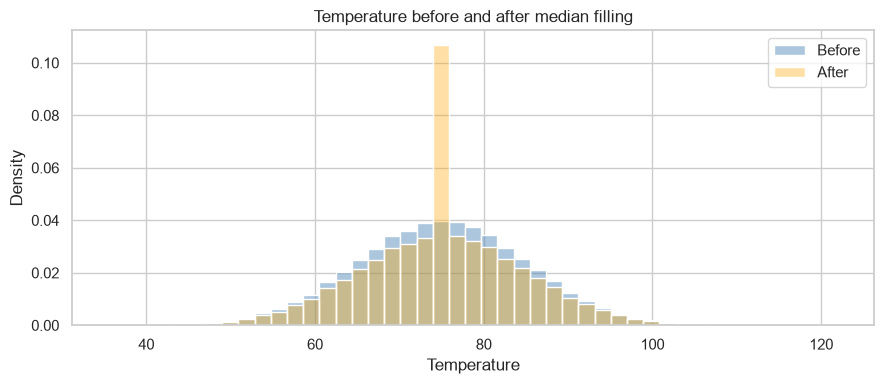

In [6]:
time_df = df.sort_values("timestamp").reset_index(drop=True)
split = int(len(time_df) * 0.80)
train_rows = time_df.iloc[:split]
train_median = train_rows["temperature"].median()

eda_filled = time_df.copy()  # Do not change the original df
eda_filled["temperature_was_missing"] = eda_filled["temperature"].isna().astype(int)
eda_filled["temperature_filled"] = eda_filled["temperature"].fillna(train_median)

print("Training rows:", split, "| Later rows:", len(time_df) - split)
print("Training median:", round(train_median, 2))
print("Missing before:", time_df["temperature"].isna().sum())
print("Missing after:", eda_filled["temperature_filled"].isna().sum())
print("Before / after summary:")
print(pd.DataFrame({
    "Before": time_df["temperature"].describe(),
    "After": eda_filled["temperature_filled"].describe()
}).round(2))

plt.figure(figsize=(9, 4))
sns.histplot(time_df["temperature"].dropna(), bins=45, stat="density", color="steelblue", alpha=0.45, label="Before")
sns.histplot(eda_filled["temperature_filled"], bins=45, stat="density", color="orange", alpha=0.35, label="After")
plt.title("Temperature before and after median filling")
plt.xlabel("Temperature")
plt.legend()
plt.tight_layout()
plt.show()


**Observation:** The missing temperatures are filled in the copied dataset, so the missing count becomes zero. The histogram has a taller bar at the median because the same value replaces 14,000 readings. The rest of the shape is unchanged.

**Action:** Do this inside the pipeline, with the median calculated from the training split only.

**Reason:** A median calculated from all rows would let information from the test rows leak into training.

## 4. Check the target

The column we want to predict is `maintenance_required`. 0 means no maintenance and 1 means maintenance is needed. Check how many readings are in each class.

                      Count  Percentage
maintenance_required                   
0                     80303        80.3
1                     19697        19.7


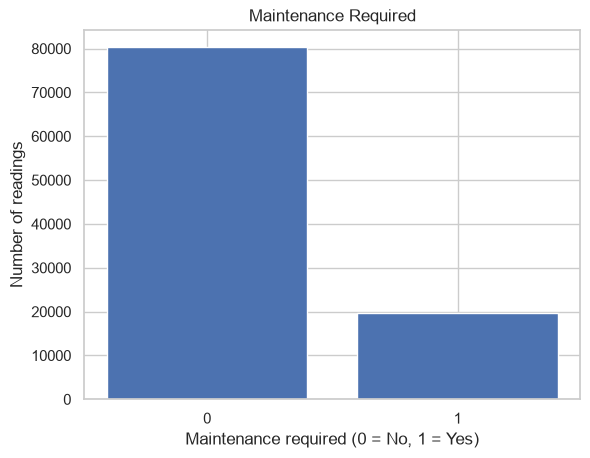

In [7]:
counts = df["maintenance_required"].value_counts().sort_index()
print(pd.DataFrame({"Count": counts, "Percentage": (counts / len(df) * 100).round(2)}))
plt.bar(counts.index.astype(str), counts.values)
plt.title("Maintenance Required")
plt.xlabel("Maintenance required (0 = No, 1 = Yes)")
plt.ylabel("Number of readings")
plt.show()


**Observation:** About 80% of the readings are class 0 and 20% are class 1.

**Action:** Judge the models with precision, recall, F1-score and the confusion matrix, not accuracy alone.

**Reason:** A model that always guessed 0 would reach about 80% accuracy without finding a single machine that needs maintenance.

## 5. Look at the sensor values

Use histograms to see the spread of the readings and check for values that look odd.

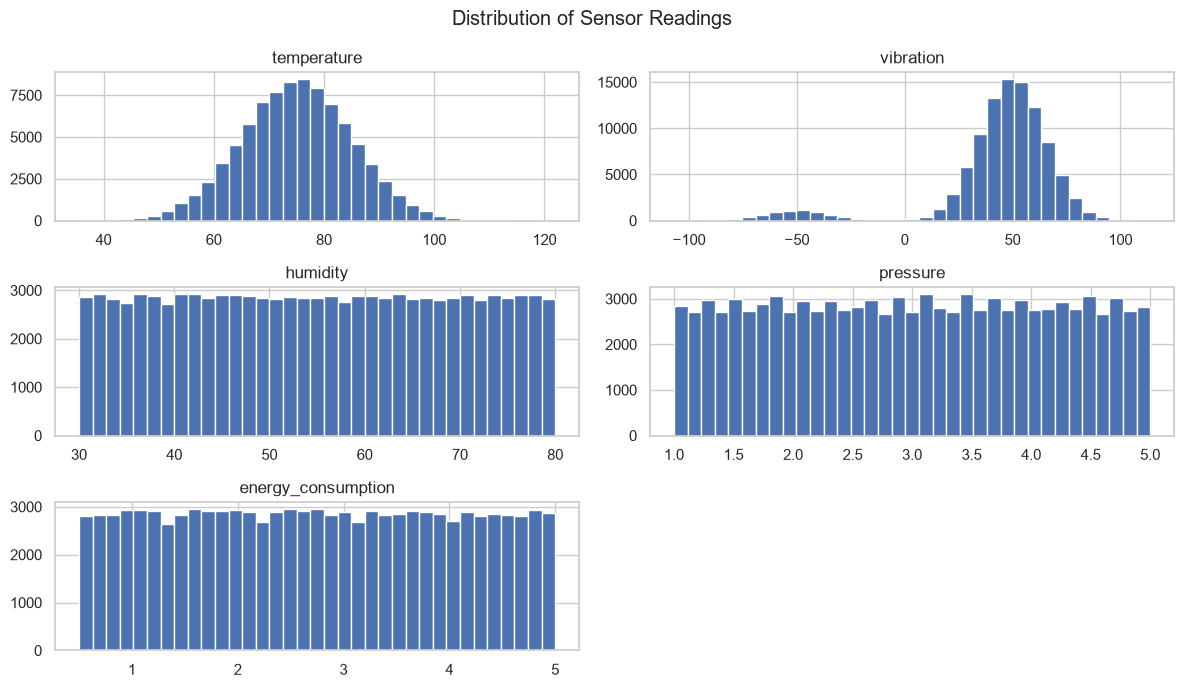

In [8]:
sensor_cols = ["temperature", "vibration", "humidity", "pressure", "energy_consumption"]
df[sensor_cols].hist(bins=35, figsize=(12, 7))
plt.suptitle("Distribution of Sensor Readings")
plt.tight_layout()
plt.show()


**Observation:** Humidity, pressure and energy consumption are spread evenly across their ranges (flat histograms). Temperature is bell-shaped around 75. Raw vibration is mostly positive around 50, with a smaller group of negative readings.

**Action:** Look at the negative vibration readings more closely.

**Reason:** One sensor producing a second group of mirrored negative values is unusual, so it needs an explanation before modelling.

### Check negative vibration readings

I noticed some vibration values are below zero, so I check how many there are and compare their maintenance rates.

In [9]:
negative = df["vibration"] < 0
comparison = df.groupby(negative).agg(
    readings=("vibration", "size"),
    avg_size=("vibration", lambda s: s.abs().mean()),
    maintenance_rate=("maintenance_required", "mean")
)
comparison.index = ["Non-negative", "Negative"]
comparison["maintenance_rate"] *= 100
print(comparison.round(2))
print("Negative vibration percentage:", round(negative.mean() * 100, 2), "%")


              readings  avg_size  maintenance_rate
Non-negative     93297     50.02             19.70
Negative          6703     49.91             19.59
Negative vibration percentage: 6.7 %


**Observation:** About 6.7% of vibration readings are negative. Their average size (about 49.9) and maintenance rate (19.6%) are almost the same as for non-negative readings (about 50.0 and 19.7%). The size of vibration forms one bell shape around 50 once the sign is removed (chart below). This suggests the sign adds nothing, but it does not prove a sensor error.

**Action:** Add `vibration_abs` as a feature and test it against the original `vibration` column.

**Reason:** The size of the vibration looks informative, while the direction shows no measurable difference in this dataset.

In [10]:
df["vibration_abs"] = df["vibration"].abs()
df[["vibration", "vibration_abs"]].head()


,vibration,vibration_abs
0,-28.65,28.65
1,57.28,57.28
2,50.20,50.20
3,37.65,37.65
4,40.69,40.69


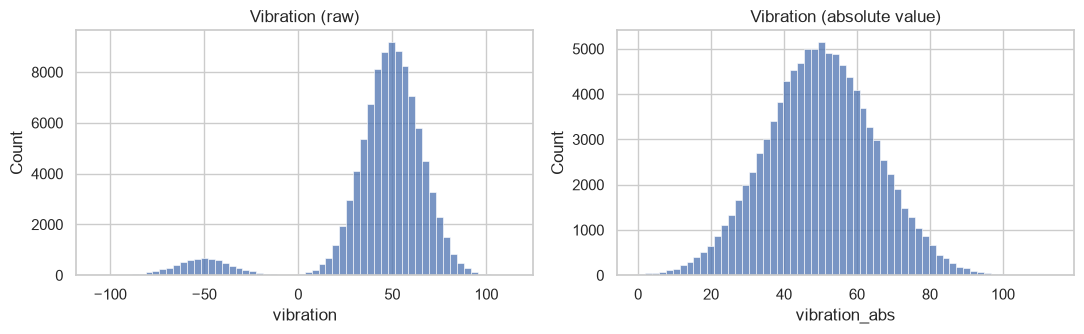

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
sns.histplot(df["vibration"], bins=60, ax=axes[0]); axes[0].set_title("Vibration (raw)")
sns.histplot(df["vibration_abs"], bins=60, ax=axes[1]); axes[1].set_title("Vibration (absolute value)")
plt.tight_layout()
plt.show()

## 6. Check outliers

Use boxplots and the IQR method to find readings that are much higher or lower than most of the data.

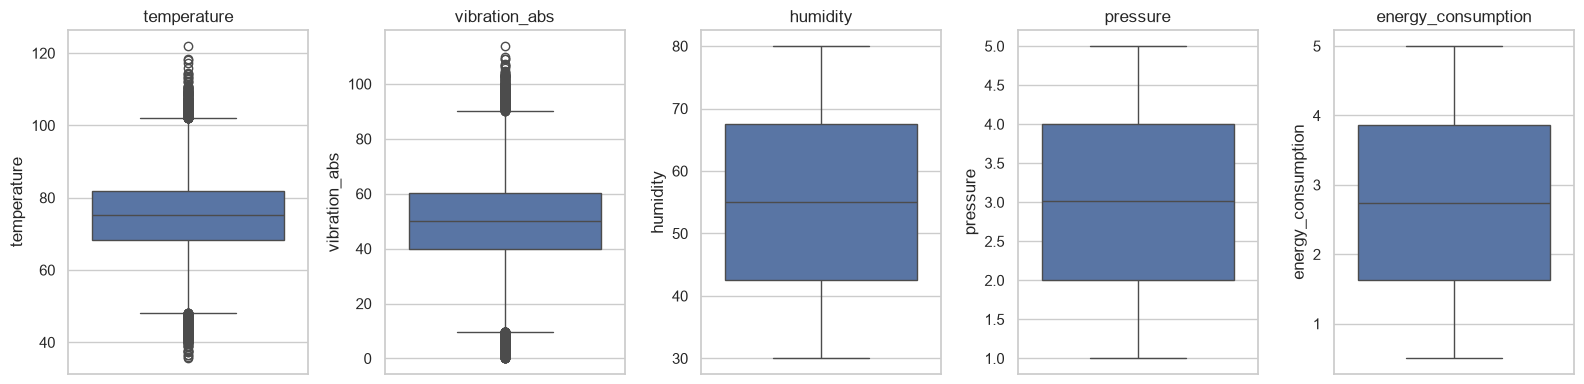

,Outlier count
temperature,649
vibration_abs,714
humidity,0
pressure,0
energy_consumption,0


In [12]:
outlier_cols = ["temperature", "vibration_abs", "humidity", "pressure", "energy_consumption"]
fig, axes = plt.subplots(1, 5, figsize=(16, 4))
for ax, col in zip(axes, outlier_cols):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

def count_iqr_outliers(values):
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((values < q1 - 1.5 * iqr) | (values > q3 + 1.5 * iqr)).sum())

pd.DataFrame({"Outlier count": {c: count_iqr_outliers(df[c].dropna()) for c in outlier_cols}})


**Observation:** The IQR method flags 649 temperature readings and 714 vibration readings as outliers (under 1% of rows each). Humidity, pressure and energy consumption have none, which fits their flat shapes.

**Action:** Keep these values for now.

**Reason:** A value outside the usual range is not automatically wrong, and unusually high readings might be signs that a machine needs maintenance. The next check compares them with the anomaly flag.

### Check extreme sensor readings against the anomaly flag

Also check whether the really high temperature and vibration readings appear in the anomaly rows.

In [13]:
print("Temperature and vibration ranges by anomaly flag:")
print(df.groupby("anomaly_flag")[["temperature", "vibration"]].agg(["min", "max"]).round(2))

extreme_temp = df["temperature"] > 90
extreme_vibration = df["vibration"].abs() > 80
print("\nTemperature > 90 vs anomaly flag:")
print(pd.crosstab(extreme_temp, df["anomaly_flag"]))
print("\nAbsolute vibration > 80 vs anomaly flag:")
print(pd.crosstab(extreme_vibration, df["anomaly_flag"]))


Temperature and vibration ranges by anomaly flag:
             temperature         vibration       
                     min     max       min    max
anomaly_flag                                     
0                  35.55   90.00    -79.98   80.0
1                  41.71  121.94   -106.98  113.8

Temperature > 90 vs anomaly flag:
anomaly_flag      0     1
temperature              
False         91084  3084
True              0  5832

Absolute vibration > 80 vs anomaly flag:
anomaly_flag      0     1
vibration                
False         91084  6632
True              0  2284


In [14]:
# How many IQR outliers are anomaly rows?
for col in ["temperature", "vibration_abs"]:
    q1, q3 = df[col].quantile([0.25, 0.75]); iqr = q3 - q1
    is_out = (df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)
    print(f"{col}: {is_out.sum()} outliers, {(is_out & (df['anomaly_flag'] == 1)).sum()} of them are anomaly rows")

temperature: 649 outliers, 310 of them are anomaly rows
vibration_abs: 714 outliers, 373 of them are anomaly rows


**Observation:** Rows without an anomaly flag never go above 90 for temperature and stay between about -80 and 80 for vibration. Every reading above those limits (5,832 temperature and 2,284 vibration readings) is in an anomaly-flagged row. About half of the IQR outliers are anomaly rows, so not every IQR outlier is an anomaly.

**Action:** Keep the extreme readings.

**Reason:** They are tied to the anomaly labels, so removing them would throw away useful information. It also shows the anomaly flag follows these sensor limits, which matters for the leakage check in section 8.

## 7. Check which columns relate to maintenance

Use a heatmap and a few graphs to compare the columns with `maintenance_required`.

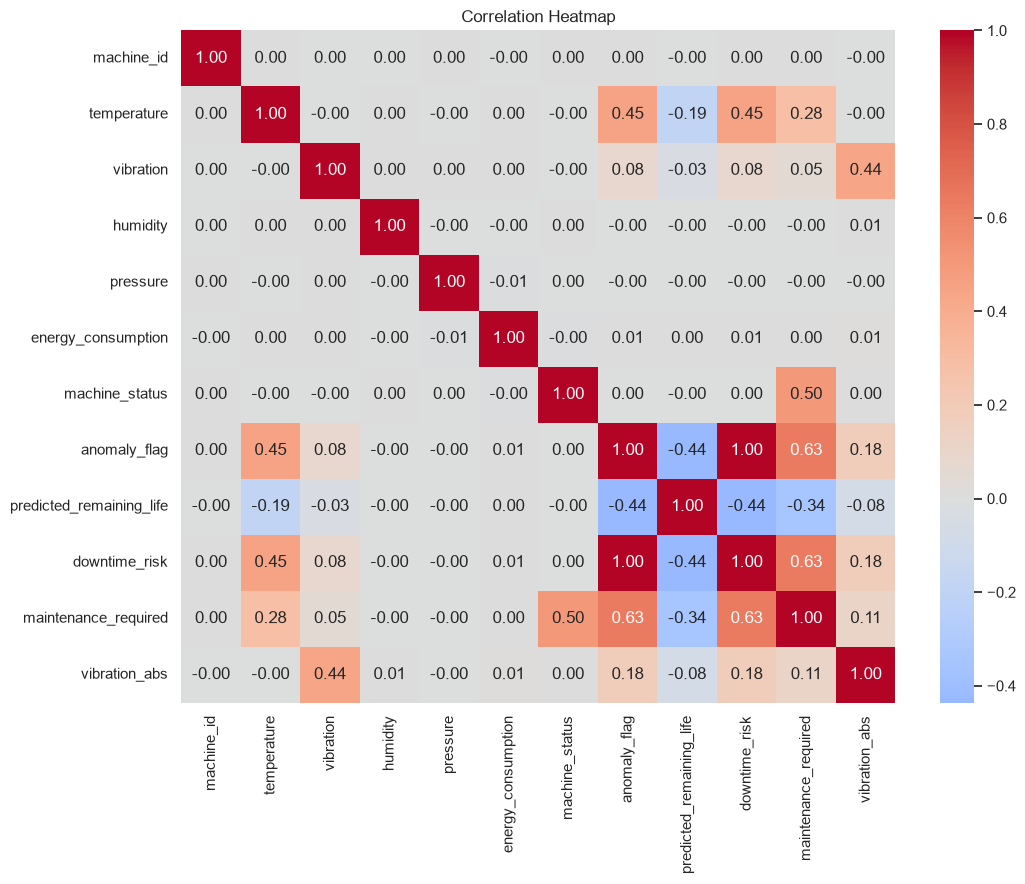

maintenance_required        1.000000
anomaly_flag                0.631728
downtime_risk               0.631726
machine_status              0.503827
temperature                 0.282663
vibration_abs               0.113162
vibration                   0.051313
machine_id                  0.002537
energy_consumption          0.001384
pressure                   -0.001945
humidity                   -0.003815
predicted_remaining_life   -0.342990
Name: maintenance_required, dtype: float64

In [15]:
corr = df.select_dtypes(include="number").corr()
plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()
corr["maintenance_required"].sort_values(ascending=False)


**Observation:** `downtime_risk` and `anomaly_flag` (both about 0.63) and `machine_status` (about 0.50) have the strongest links with maintenance. Temperature has a moderate positive correlation (about 0.28) and `predicted_remaining_life` a negative one (about -0.34). Humidity, pressure and energy consumption are close to zero.

**Action:** Test temperature in the models. Do not drop the near-zero columns on this graph alone, and run a leakage check on the strong derived columns.

**Reason:** Pearson correlation only measures straight-line relationships, so a near-zero value does not rule out another pattern. The strong derived columns may be giving away the answer.

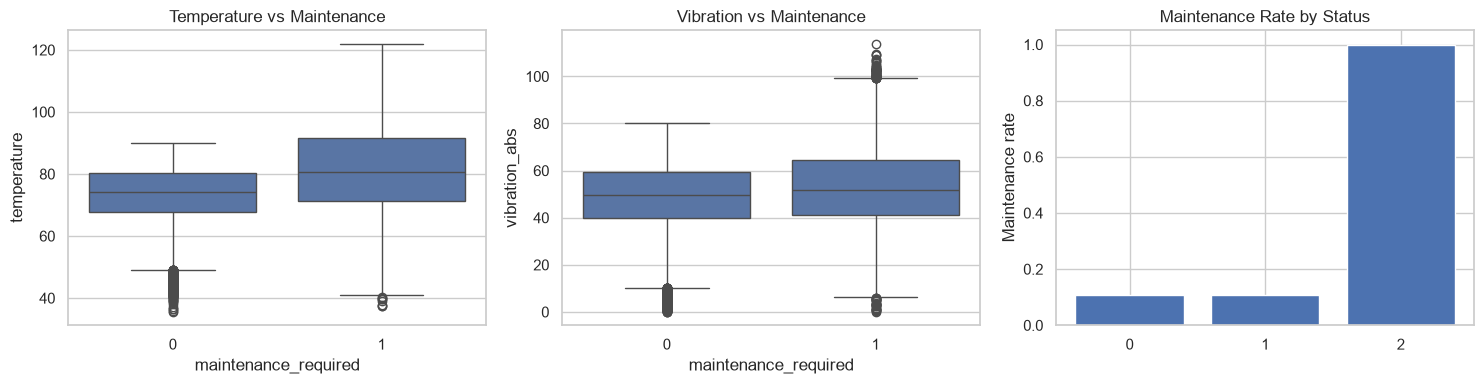

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(data=df, x="maintenance_required", y="temperature", ax=axes[0])
axes[0].set_title("Temperature vs Maintenance")
sns.boxplot(data=df, x="maintenance_required", y="vibration_abs", ax=axes[1])
axes[1].set_title("Vibration vs Maintenance")
rates = df.groupby("machine_status")["maintenance_required"].mean()
axes[2].bar(rates.index.astype(str), rates.values)
axes[2].set_title("Maintenance Rate by Status")
axes[2].set_ylabel("Maintenance rate")
plt.tight_layout()
plt.show()


**Observation:** Temperature is higher when maintenance is needed. Vibration shows a smaller difference (averages in section 10). Every reading with `machine_status = 2` needs maintenance (100%), compared with about 11% for status 0 and 1.

**Action:** Test temperature and vibration in the models, and treat `machine_status` with care.

**Reason:** Status 2 means the machine has already failed, which the model may not know in advance.

## 8. Check for data leakage

Data leakage is when the model gets information it would not have at the time of prediction. Check if any columns make the answer too obvious.

In [17]:
for col in ["anomaly_flag", "machine_status", "failure_type"]:
    print("\n", col)
    print(pd.crosstab(df[col], df["maintenance_required"]))



 anomaly_flag
maintenance_required      0      1
anomaly_flag                      
0                     80303  10781
1                         0   8916

 machine_status
maintenance_required      0      1
machine_status                    
0                      8776   1076
1                     71527   8564
2                         0  10057

 failure_type
maintenance_required      0      1
failure_type                      
Electrical Fault          0   1014
Normal                80303  11596
Overheating               0   1989
Pressure Drop             0   1969
Vibration Issue           0   3129


**Observation:** `anomaly_flag = 1`, `machine_status = 2` and non-Normal `failure_type` only appear in maintenance class 1.

**Action:** Check `downtime_risk` and `predicted_remaining_life` below.

**Reason:** If these columns are not known when a prediction is made, a model that uses them would look better than it really is.

In [18]:
print("Anomaly flag compared with downtime risk:")
print(pd.crosstab(df["anomaly_flag"], df["downtime_risk"] > 0))
print("\nDowntime risk range for each flag:")
print(df.groupby("anomaly_flag")["downtime_risk"].agg(["min", "max", "mean"]).round(3))

unflagged_maintenance = df[
    (df["maintenance_required"] == 1) &
    (df["anomaly_flag"] == 0) &
    (df["downtime_risk"] == 0)
]
print("\nMaintenance rows with neither flag:", len(unflagged_maintenance))
print("Remaining-life summary for those rows:")
print(unflagged_maintenance["predicted_remaining_life"].describe().round(2))
print("Percent with remaining life <= 24:",
      round(unflagged_maintenance["predicted_remaining_life"].le(24).mean() * 100, 2), "%")
print("\nMaintenance by remaining life <= 24:")
print(pd.crosstab(df["predicted_remaining_life"] <= 24,
                  df["maintenance_required"], normalize="index").mul(100).round(2))


Anomaly flag compared with downtime risk:
downtime_risk  False  True 
anomaly_flag               
0              91084      0
1                  0   8916

Downtime risk range for each flag:
               min  max  mean
anomaly_flag                 
0             0.00  0.0   0.0
1             0.88  1.0   1.0

Maintenance rows with neither flag: 10781
Remaining-life summary for those rows:
count    10781.00
mean       217.48
std        156.51
min         10.00
25%         64.00
50%        211.00
75%        354.00
max        499.00
Name: predicted_remaining_life, dtype: float64
Percent with remaining life <= 24: 18.03 %

Maintenance by remaining life <= 24:
maintenance_required          0      1
predicted_remaining_life              
False                     85.58  14.42
True                      11.53  88.47


**Observation:** `downtime_risk > 0` matches `anomaly_flag = 1` exactly, so it is a duplicate. There are **10,781** maintenance rows with neither flag. Their median predicted remaining life is **211**, and only around **18%** have 24 or fewer hours remaining. Most of them (9,133) are explained by `machine_status = 2` or a non-Normal `failure_type`. The next cell looks at the rest.

**Action:** Check the rows that no flag, status or failure type explains.

In [19]:
# Maintenance rows that no flag, status or failure type explains
explained = (unflagged_maintenance["failure_type"] != "Normal") | (unflagged_maintenance["machine_status"] == 2)
residual = unflagged_maintenance[~explained]
print("Unflagged maintenance rows explained by status/failure type:", explained.sum())
print("Rows nothing explains:", len(residual))
print("Their remaining life <= 24:", round(residual["predicted_remaining_life"].le(24).mean() * 100, 1), "%")
print("Their median remaining life:", residual["predicted_remaining_life"].median())

low_life = df["predicted_remaining_life"] <= 24
print("\nReadings with remaining life <= 24:", low_life.sum())
print("Maintenance rate for them:", round(df.loc[low_life, "maintenance_required"].mean() * 100, 1), "%")

Unflagged maintenance rows explained by status/failure type: 9133
Rows nothing explains: 1648
Their remaining life <= 24: 100.0 %
Their median remaining life: 14.0

Readings with remaining life <= 24: 7127
Maintenance rate for them: 88.5 %


**Observation:** The 1,648 maintenance rows that nothing else explains all have a remaining life of 24 hours or less (median 14). Across the whole dataset, readings with 24 or fewer hours remaining are maintenance 88.5% of the time (7,127 readings).

**Action:** Treat `predicted_remaining_life` as a very strong feature and find out how it is produced before using it.

**Reason:** If it is calculated using knowledge of the maintenance outcome, it would not be available at prediction time. If it is an estimate from a separate model, it may be legitimate.

In [20]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import f1_score, precision_score, recall_score

# Quick check only (not the final model): how much do the borderline columns add?
q = df.sort_values("timestamp").reset_index(drop=True)
cut = int(len(q) * 0.80)                       # time-ordered split
train, test = q.iloc[:cut], q.iloc[cut:]
sensors = ["temperature", "vibration_abs", "humidity", "pressure", "energy_consumption"]
feature_sets = {
    "A: sensors only": sensors,
    "B: A + machine_status": sensors + ["machine_status"],
    "C: B + predicted_remaining_life": sensors + ["machine_status", "predicted_remaining_life"],
}
rows = []
for name, cols in feature_sets.items():
    model = HistGradientBoostingClassifier(random_state=0).fit(train[cols], train["maintenance_required"])
    pred = model.predict(test[cols])
    rows.append({"Feature set": name,
                 "Precision": precision_score(test["maintenance_required"], pred),
                 "Recall": recall_score(test["maintenance_required"], pred),
                 "F1": f1_score(test["maintenance_required"], pred)})
pd.DataFrame(rows).set_index("Feature set").round(3)

,Precision,Recall,F1
Feature set,,,
A: sensors only,0.990,0.404,0.574
B: A + machine_status,0.995,0.867,0.927
C: B + predicted_remaining_life,0.989,0.983,0.986


**Observation:** With sensors only (A), the model finds only about 40% of the maintenance readings (recall 0.40, F1 0.57). Adding `machine_status` (B) lifts recall to about 0.87 and F1 to 0.93. Adding `predicted_remaining_life` (C) brings both close to 0.98.

**Reason:** The sensors alone are a weak predictor, so the choice of the two derived columns changes the results a lot. A and C are the two honest ends of the range: the strict "predict before anything fails" case, and the case where those columns are available.

### Working decision on the columns (team to confirm)

**Action:**
- Do not use `anomaly_flag`, `downtime_risk` or `failure_type` as inputs. They give away the answer on their own.
- Train the models on two feature sets and report both: sensors only (A), and sensors plus `machine_status` and `predicted_remaining_life` (C).
- Confirm with the lecturer whether `machine_status` and `predicted_remaining_life` are available at prediction time.

**Reason:** This avoids inflated results while still showing how much the extra columns help.

## 9. Compare the machines

There are 50 machines, so I check whether some have more maintenance readings than others.

            mean  count  maintenance_percent
machine_id                                  
43          0.22   1906                21.51
50          0.21   1912                21.44
24          0.21   1984                21.07
32          0.21   2031                20.97
5           0.21   2043                20.95
29          0.21   2044                20.89
30          0.21   2074                20.88
6           0.21   1934                20.84
42          0.21   2019                20.65
4           0.21   2004                20.61


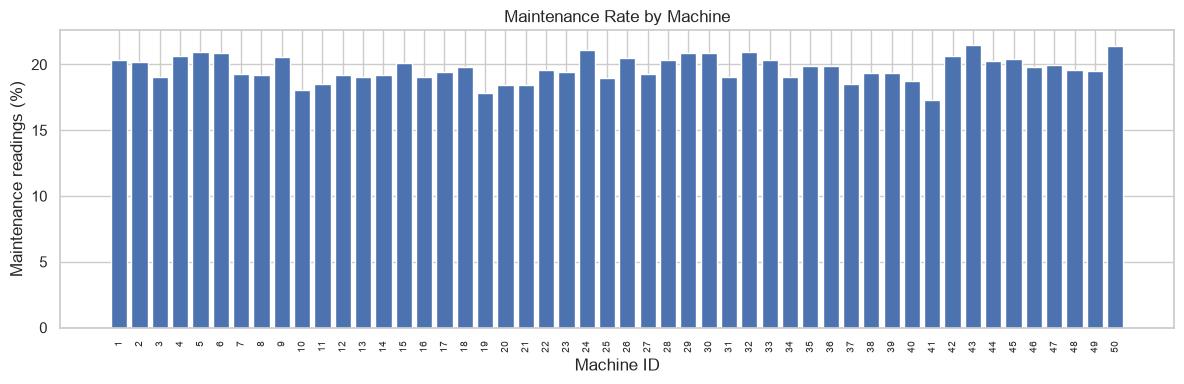

In [21]:
machine_rates = df.groupby("machine_id")["maintenance_required"].agg(["mean", "count"])
machine_rates["maintenance_percent"] = machine_rates["mean"] * 100
print(machine_rates.sort_values("maintenance_percent", ascending=False).head(10).round(2))
plt.figure(figsize=(12, 4))
plt.bar(machine_rates.index.astype(str), machine_rates["maintenance_percent"])
plt.xticks(rotation=90, fontsize=7)
plt.title("Maintenance Rate by Machine")
plt.xlabel("Machine ID")
plt.ylabel("Maintenance readings (%)")
plt.tight_layout()
plt.show()


**Observation:** Maintenance rates are quite similar across the 50 machines, from about 17.3% to 21.5%. No machine stands out.

**Action:** Do not use `machine_id` as a feature.

**Reason:** It carries almost no signal, and it is a label, not a quantity, so using it as a number would imply an order that does not exist.

## 10. Compare readings for class 0 and class 1

I compare the average sensor values for readings with and without maintenance.

In [22]:
summary = df.groupby("maintenance_required")[["temperature", "vibration_abs", "humidity", "pressure", "energy_consumption"]].mean().round(2)
summary


,temperature,vibration_abs,humidity,pressure,energy_consumption
maintenance_required,,,,,
0,73.63,49.18,55.02,3.0,2.75
1,80.75,53.44,54.88,3.0,2.75


**Observation:** The maintenance class has a higher average temperature (about 80.75 compared with 73.63) and a higher absolute vibration (about 53.44 compared with 49.18). Humidity, pressure and energy consumption have almost the same averages in both classes.

**Action:** Prioritise temperature and vibration in the models, and still include the other sensors in the first tests.

**Reason:** Averages alone do not show every possible relationship, so the other sensors should be tested before they are dropped.

## 11. What I found

These are the main points from my EDA:

- There are 100,000 readings from 50 machines, with different ranges for each sensor.
- Temperature has 14% missing values. They look random, so I will fill them with the training-set median and add a missing indicator. I tested this on the earlier 80% of rows.
- Around 80% of readings are class 0, so I will judge models with recall, precision and F1-score as well as accuracy.
- About 6.7% of vibration readings are negative, but their size and maintenance rate match the positive readings, so I will test `vibration_abs`.
- Extreme temperature and vibration readings are linked to anomaly rows, so I will keep them.
- Temperature and vibration differ more between the maintenance classes than humidity, pressure and energy consumption.
- `anomaly_flag`, `downtime_risk` and `failure_type` give away the answer and will not be used. `machine_status` and `predicted_remaining_life` help a lot (F1 0.57 for sensors only, 0.93 with status, 0.99 with both), so the models will be reported on two feature sets.
- Maintenance rates across machines are similar, so machine ID will not be used.

**Next step:** In Week 7, our group will put the cleaning steps into the ML pipeline, train at least three models and compare their results. This EDA does not change the original CSV.